# 31 · 线性代数与张量形状

公用基础路径：31 → 32 → 33 → 34，再进入搜索、广告或推荐。

**范围：小数组构造机制实验，CPU执行，无真实日志、无正式模型训练或业务收益主张。**

每节先预测 → 只改一个变量 → 运行 → 解释。首次从头执行，后续修改时重跑相关下游格。

## 输入与线性映射

样本矩阵 X 是 [样本,特征]；权重 W 是 [特征,输出]。矩阵乘法对共享的特征轴求和。先预测输出形状，再运行。

In [1]:
import torch
import matplotlib.pyplot as plt
torch.set_num_threads(1)
X = torch.tensor([[1., 2.], [3., 4.], [0., 1.]])
W = torch.tensor([[2.], [-1.]])
scores = X @ W
assert scores.shape == (3, 1)
assert torch.equal(scores, (X * W.T).sum(1, keepdim=True))
print('X, W, scores:', X.shape, W.shape, scores.flatten().tolist())

X, W, scores: torch.Size([3, 2]) torch.Size([2, 1]) [0.0, 2.0, -1.0]


## 只改一个变量：特征单位

把第一个特征放大10倍，权重不动。预测评分是否不变。

In [2]:
scaled = X.clone()
scaled[:, 0] *= 10
changed = scaled @ W
assert not torch.equal(scores, changed)
print(torch.cat([scores, changed], dim=1))

tensor([[ 0., 18.],
        [ 2., 56.],
        [-1., -1.]])


## 广播陷阱

[3,1] 减 [3] 能运行，却产生 [3,3]。标签轴必须显式对齐。

In [3]:
y = torch.tensor([0., 1., 0.])
wrong = scores - y
right = scores.squeeze(-1) - y
assert wrong.shape == (3, 3) and right.shape == (3,)
print('错误广播 / 正确逐样本残差:', wrong.shape, right.tolist())

错误广播 / 正确逐样本残差: torch.Size([3, 3]) [0.0, 1.0, -1.0]


## 补偿单位与图像

这次只把新坐标下对应权重除10；核对线性关系。

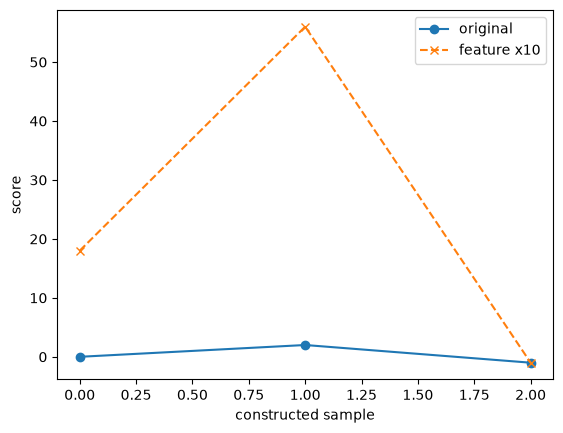

In [4]:
compensated = W.clone()
compensated[0] /= 10
assert torch.allclose(scaled @ compensated, scores)
plt.plot(scores.flatten(), 'o-', label='original')
plt.plot(changed.flatten(), 'x--', label='feature x10')
plt.xlabel('constructed sample'); plt.ylabel('score'); plt.legend(); plt.show()

## 解释练习

解释：为何单位变化能改变内积？为什么广播没有报错却改变了损失含义？把两列特征改为四列前，列出所有应修改的形状。

在下格记录预测、实际结果、差异原因与适用边界；保留失败结果。

In [5]:
reflection = {'预测': '', '结果': '', '解释与边界': ''}
reflection

{'预测': '', '结果': '', '解释与边界': ''}